In [2]:
import pandas as pd

In [3]:
df = pd.read_csv('nsduh_2021_2024.csv')

/var/folders/mt/1pxgdqcd35z_dh18p8pv9w100000gn/T/ipykernel_50078/622799189.py:1: DtypeWarning: Columns (2281) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('nsduh_2021_2024.csv')


In [4]:
df.head()

,YEAR,AGE3,PDEN10,NEWRACE2,IRINSUR4,IRHHSIZ2,IRPINC3,IRFAMIN3,IRKI17_2,IRHH65_2,...,ANYNEDFLAG,ANYNEDYR,FPIMFNMYR,ILIMFOTHFG,ILIMFOTHYR,ILIMFOTHMN,ANALWT2_C1,ANALWT2_C2,ANALWT2_C3,ANALWT2_C4
0,2021,8,2,1,1,2,2,2,2,1,...,-9.0,-9.0,-9,-9,-9,-9,732.884779,366.442389,244.294926,183.221195
1,2021,11,1,1,1,2,7,7,1,3,...,-9.0,-9.0,-9,-9,-9,-9,11710.016142,5855.008071,3903.338714,2927.504035
2,2021,6,2,1,1,2,1,4,1,1,...,-9.0,-9.0,-9,-9,-9,-9,466.934414,233.467207,155.644805,116.733603
3,2021,9,1,1,1,3,1,3,2,1,...,-9.0,-9.0,-9,-9,-9,-9,11070.439576,5535.219788,3690.146525,2767.609894
4,2021,6,1,7,2,1,1,1,1,1,...,-9.0,-9.0,-9,-9,-9,-9,218.379769,109.189885,72.793256,54.594942


In [5]:
wanted_var = ["QUESTID2", "YEAR", "ANALWT2_C4", "AGE3", "IRSEX", "NEWRACE2", "POVERTY3","IMOTHER", "IFATHER", "IRHHSIZ2", "IRALCAGE", "IRCIGAGE", "IRNICVAPAGE", "IRMJAGE",
              "ALCFLAG", "CIGFLAG", "NICVAPFLAG", "MRJFLAG", "IRALCFY", "IRMJFY", "IRALCRC", "IRMJRC", "YELSTGRD", "YESCHFLT", "YMDEYR", "YMDELT",
              "YEPCHKHW", "YEPHLPHW", "YEPLMTSN", "YEPPROUD", "YEYARGUP", "YESTSALC", "YEFMJEVR", "YEPMJEVR", "YERLGIMP", "INHALFLAG", "IRINHALAGE"]

all_columns = df.columns
missing = []
for c in wanted_var:
    if c not in all_columns:
        missing.append(c)

print("Columns in file:", len(all_columns))
print("Missing columns:", missing)


Columns in file: 2638
Missing columns: []


In [6]:
use = []
for c in wanted_var:
    if c in all_columns:
        use.append(c)


df = df[use]
print("All respondents:", df.shape)

All respondents: (232441, 37)


In [7]:
teens = df[df["AGE3"].isin([1, 2, 3])].copy()

print("Teens ages 12-17:", teens.shape)

Teens ages 12-17: (45618, 37)


In [8]:
print(pd.crosstab(teens["YEAR"], teens["AGE3"], margins=True))

AGE3      1      2      3    All
YEAR                            
2021   3654   3579   3510  10743
2022   3926   4284   3759  11969
2023   3649   4067   3856  11572
2024   3527   3932   3875  11334
All   14756  15862  15000  45618


In [9]:
import numpy as np

In [10]:
raw = teens.copy()

In [11]:
bad_codes = [-9, 85, 94, 97, 98, 99]

In [12]:
# Age of first use: i am deciding to keeping real ages only, not including 991 = never and -9 = not asked
age_vars = ["IRALCAGE", "IRCIGAGE", "IRNICVAPAGE", "IRMJAGE", "IRINHALAGE"]
teens[age_vars] = teens[age_vars].where((teens[age_vars] > 0) & (teens[age_vars] < 900))

In [13]:
survey_vars = ["YELSTGRD", "YESCHFLT", "YEPCHKHW", "YEPHLPHW", "YEPLMTSN", "YEPPROUD", "YEYARGUP", "YESTSALC", "YEFMJEVR", "YEPMJEVR", "YERLGIMP"]

for c in survey_vars:
    if c in teens.columns:
        teens[c] = teens[c].replace(bad_codes, np.nan)

In [14]:
#Grades: 5 = "school doesn't give grades"
teens["YELSTGRD"] = teens["YELSTGRD"].replace(5, np.nan)

In [15]:
for c in ["IMOTHER", "IFATHER"]:
    teens[c] = teens[c].replace(3, np.nan)

In [16]:
for c in ["ALCFLAG", "CIGFLAG", "NICVAPFLAG", "MRJFLAG"]:
    teens[c] = teens[c].replace(-9, np.nan)

In [17]:
# Ever used flags: -9 = not asked that year
for c in ["ALCFLAG", "CIGFLAG", "NICVAPFLAG", "MRJFLAG", "INHALFLAG"]:
    teens[c] = teens[c].replace(-9, np.nan)

# Days used in past year: never or not in past year . Replacing that with 0
for c in ["IRALCFY", "IRMJFY"]:
    teens[c] = teens[c].replace([991, 993], 0)

# Before vs after report
report = pd.DataFrame({
    "blank_before": raw.isna().sum(),
    "blank_after": teens.isna().sum(),
})

report["percent_blank_after"] = (report["blank_after"] / len(teens) * 100)
print(report.sort_values("percent_blank_after", ascending=False))

             blank_before  blank_after  percent_blank_after
IRINHALAGE              0        42745            93.702047
IRCIGAGE                0        42277            92.676137
IRMJAGE                 0        39094            85.698628
IRNICVAPAGE             0        38364            84.098382
IRALCAGE                0        35266            77.307203
YEFMJEVR                0        12070            26.458854
YEPMJEVR                0        11938            26.169494
INHALFLAG               0        11334            24.845456
NICVAPFLAG              0        10743            23.549915
YELSTGRD                0         6306            13.823491
YESTSALC                0         5279            11.572186
YEPLMTSN                0         4564            10.004823
YEPHLPHW                0         3775             8.275242
YEPCHKHW                0         3704             8.119602
YESCHFLT                0         3507             7.687755
YMDEYR               1790         1790  

In [18]:
print([c for c in all_columns if "MDE" in c])

['AD_MDEA1', 'AD_MDEA2', 'AD_MDEA3', 'AD_MDEA4', 'AD_MDEA5', 'AD_MDEA6', 'AD_MDEA7', 'AD_MDEA8', 'ADSMMDEA', 'YO_MDEA1', 'YO_MDEA2', 'YO_MDEA3', 'YO_MDEA4', 'YO_MDEA5', 'YO_MDEA6', 'YO_MDEA7', 'YO_MDEA8', 'YODSMMDE', 'ATXMDEYR', 'ARXMDEYR', 'AMDETXRX', 'ADOCMDE', 'AOMDMDE', 'APSY1MDE', 'APSY2MDE', 'ASOCMDE', 'ACOUNMDE', 'ANURSMDE', 'ARELMDE', 'AHBCHMDE', 'AALTMDE', 'YMDELT', 'YMDEYR', 'YTXMDEYR', 'YRXMDEYR', 'YMDETXRX', 'YDOCMDE', 'YOMDMDE', 'YPSY1MDE', 'YPSY2MDE', 'YSOCMDE', 'YCOUNMDE', 'YNURSMDE', 'YRELMDE', 'YHBCHMDE', 'YALTMDE', 'MDEIMPY', 'AOMHMDE', 'AHLTMDE', 'YOMHMDE', 'YHLTMDE', 'YMDEHPRX', 'YMDEHPO', 'YMDERXO2', 'YMDEHARX', 'YMDEAUD5YR', 'YMDEIMAD5YR', 'AMDELT', 'AMDEYR', 'AMDEIMP', 'IRAMDELT', 'IIAMDELT', 'IRAMDEYR', 'IIAMDEYR', 'IRAMDEIMP', 'IIAMDEIMP', 'YMDERSUD5ANY', 'YMDESUD5ANYO']


In [19]:
print(teens.groupby("YEAR")[["YEFMJEVR", "YEPMJEVR", "NICVAPFLAG"]].apply(lambda g: g.isna().mean().round(2)))

      YEFMJEVR  YEPMJEVR  NICVAPFLAG
YEAR                                
2021      0.02      0.01         1.0
2022      0.02      0.02         0.0
2023      0.02      0.02         0.0
2024      1.00      1.00         0.0


In [20]:
for c in ["YMDEYR", "YMDELT"]:
    teens[c] = pd.to_numeric(teens[c], errors="coerce")

In [21]:
print(teens.shape)                                    
print(teens["YMDEYR"].value_counts(dropna=False))

(45618, 37)
YMDEYR
2.0    35654
1.0     8174
NaN     1790
Name: count, dtype: int64


In [22]:
#Our dataset interviews some more groups than others, so they have enough people to study 
#Each respondent has a weight. Roughly how many real americans that person stands for. 

#We'll now describe who the teens are: their age, sex, race, poverty level and family structure.


# We'll show 
# n = how many teens are actually in our data. This tells us if a group is big enough to study.
# weighted percentage= the share of all US teens this group represents. This is the number to report.


def weighted_pct(data, column, weight = 'ANALWT2_C4'):
    clean_data = data[[column, weight]].dropna()

    category_weights = clean_data.groupby(column)[weight].sum()

    total_weight = clean_data[weight].sum()

    percentage = (category_weights / total_weight) * 100

    return percentage

In [23]:
#Some feature engineering, creating a new variable: Family Structure(1 = Parent in Household, 2 = Parent not in household)

conditions = [(teens['IMOTHER'] == 1) & (teens["IFATHER"] == 1),
              (teens['IMOTHER'] == 1) & (teens["IFATHER"] == 2),
              (teens['IMOTHER'] == 2) & (teens["IFATHER"] == 1),
              (teens['IMOTHER'] == 2) & (teens["IFATHER"] == 2)]

choices = ["Both Parents", "Mother Only", "Father Only", "Neither Parent"]

teens["FAMILY"] = np.select(conditions, choices, default="Unknown")

teens['FAMILY'] = teens['FAMILY'].replace('Unknown', np.nan)

In [24]:
#Readable labels from the codebook
labels = {
    'AGE3': {1:'12-13', 2:'14-15', 3:'16-17'}, 

    'IRSEX': {1: 'Male', 2: 'Female'}, 

    'NEWRACE2': {1:'White', 2: 'Black', 3: 'Native American/AK Native',
                 4: 'Native HI/Pacific Islander', 5: 'Asian',
                 6: 'More than one race', 7: 'Hispanic'},

    'POVERTY3': {1: 'Below poverty line', 2: 'Up to 2x poverty line',
                 3: 'More than 2x poverty line'},
}


In [25]:
columns = ["AGE3", "IRSEX", "NEWRACE2", "POVERTY3", "FAMILY"]

for col in columns:
    table = pd.DataFrame(
        {
            "n": teens[col].value_counts(), 
            "weighted_percentage": weighted_pct(teens, col)
        }
    )

    if col in labels:
        table = table.rename(index = labels[col])

    print(f"\n {col}")
    print(table)


 AGE3
           n  weighted_percentage
AGE3                             
12-13  14756            32.238697
14-15  15862            34.305419
16-17  15000            33.455884

 IRSEX
            n  weighted_percentage
IRSEX                             
Male    23522            51.130347
Female  22096            48.869653

 NEWRACE2
                                n  weighted_percentage
NEWRACE2                                              
White                       20922            49.633441
Black                        6439            13.707959
Native American/AK Native    1240             0.798538
Native HI/Pacific Islander    223             0.390322
Asian                        1998             5.768370
More than one race           3163             3.642540
Hispanic                    11633            26.058830

 POVERTY3
                               n  weighted_percentage
POVERTY3                                             
Below poverty line         10410            21.140

In [26]:
#Now we will look at the age of first use 

substances = [
    ["Alcohol",    "ALCFLAG",    "IRALCAGE"],
    ["Cigarettes", "CIGFLAG",    "IRCIGAGE"],
    ["Vaping",     "NICVAPFLAG", "IRNICVAPAGE"],
    ["Marijuana",  "MRJFLAG",    "IRMJAGE"],
    ["Inhalants",  "INHALFLAG",  "IRINHALAGE"],
]

#Oldest age a teen can be now (on top of their age group)
max_age_now = teens['AGE3'].map({1:13, 2:15, 3:17})


rows = []
for name, flag, age in substances:
    is_user = teens[flag] == 1
    user_ages = teens.loc[is_user, age]
    user_max = max_age_now[is_user]

    rows.append({
        'Substance': name, 
        'Ever Used(Weighted %)': weighted_pct(teens, flag).get(1),
        'Users (n)': is_user.sum(),
        'Median first use age': user_ages.median(),
        'Youngest Age': user_ages.min(),
        'Under age 5(n)': (user_ages < 5).sum(),
        'Older than now(n)': (user_ages > user_max).sum()

        
    })
summary = pd.DataFrame(rows)
print(summary)

    Substance  Ever Used(Weighted %)  Users (n)  Median first use age  \
0     Alcohol              22.272453      10352                  14.0   
1  Cigarettes               6.746308       3341                  13.0   
2      Vaping              18.443996       7254                  14.0   
3   Marijuana              13.183965       6524                  14.0   
4   Inhalants               8.047981       2873                  11.0   

   Youngest Age  Under age 5(n)  Older than now(n)  
0           1.0              97                  0  
1           1.0              22                  0  
2           1.0               9                  0  
3           1.0               5                  0  
4           1.0              80                  0  


In [27]:
minimum_age = 5
age_vars =  ["IRALCAGE", "IRCIGAGE", "IRNICVAPAGE", "IRMJAGE", "IRINHALAGE"]

for c in age_vars:
    removed = (teens[c] < minimum_age).sum()
    teens[c] = teens[c].where(teens[c] >= minimum_age)
    print(f"{c}: removed {removed} ages under {minimum_age}")


IRALCAGE: removed 97 ages under 5
IRCIGAGE: removed 22 ages under 5
IRNICVAPAGE: removed 9 ages under 5
IRMJAGE: removed 5 ages under 5
IRINHALAGE: removed 80 ages under 5


In [28]:
print(teens["INHALFLAG"].value_counts(dropna=False))   # only 0, 1, NaN
print(teens["IRINHALAGE"].describe())          

INHALFLAG
0.0    31411
NaN    11334
1.0     2873
Name: count, dtype: int64
count    2793.000000
mean       11.172216
std         2.621145
min         5.000000
25%        10.000000
50%        12.000000
75%        13.000000
max        17.000000
Name: IRINHALAGE, dtype: float64


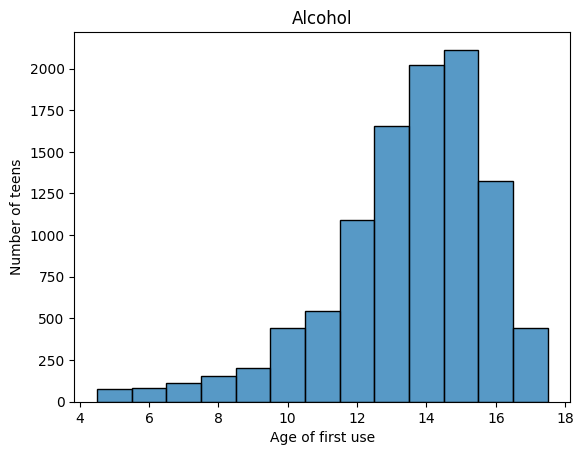

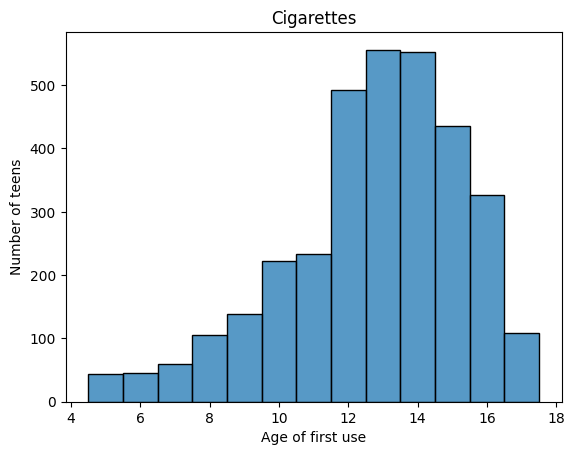

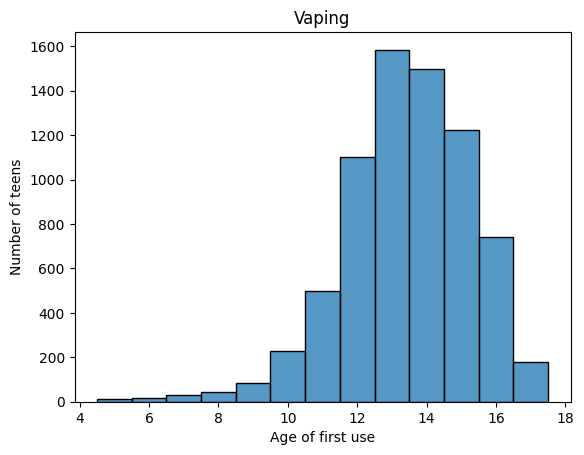

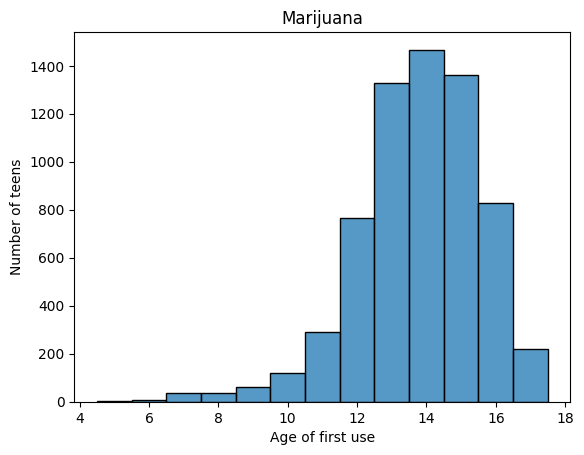

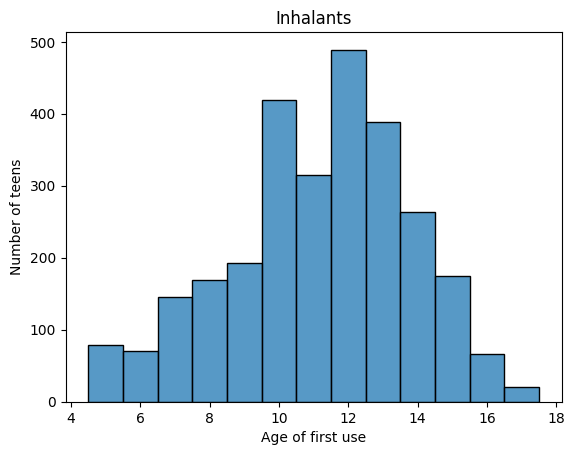

In [29]:
# Putting every user's first use age into one long table, which is labeled by substance
import seaborn as sns
import matplotlib.pyplot as plt
plot_parts = []
for name, flag, age in substances:
    part = pd.DataFrame({"Age of first use": teens.loc[teens[flag] == 1, age], "Substance": name})

    plot_parts.append(part)

plot_data = pd.concat(plot_parts, ignore_index=True)

for name, flag, age in substances:
    ages = teens.loc[teens[flag] == 1, age]     # first use ages of users only

    sns.histplot(ages, discrete=True)           
    plt.title(name)
    plt.xlabel("Age of first use")
    plt.ylabel("Number of teens")
    plt.show()


Age Group      12-13      14-15      16-17
Substance                                 
Alcohol     8.604350  19.656245  38.125925
Cigarettes  2.417643   6.237394  11.439324
Inhalants   7.109237   8.210502   8.808745
Marijuana   2.880478  11.635293  24.700589
Vaping      7.156867  18.344550  29.213817


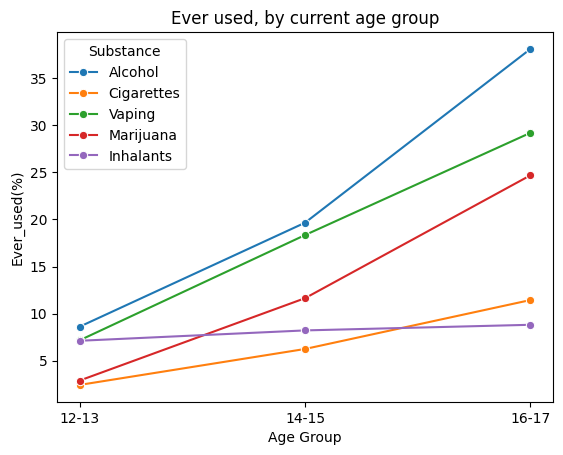

In [30]:
rows = []

for name, flag, age in substances:
    for group, label in [(1, "12-13"), (2, "14-15"), (3, "16-17")]:
        group_teens = teens[teens['AGE3'] == group]
        rows.append({
            "Substance": name, 
            "Age Group": label,
            "Ever_used(%)": weighted_pct(group_teens, flag).get(1), 
        })

by_age = pd.DataFrame(rows)

print(by_age.pivot(index="Substance", columns="Age Group", values="Ever_used(%)"))


sns.lineplot(data=by_age, x="Age Group", y="Ever_used(%)", hue="Substance", marker="o")
plt.title("Ever used, by current age group")
plt.show()

In [31]:
early_age = 14

older_teens = teens[teens["AGE3"].isin([2, 3])].copy()

for name, flag, age in substances:
    col = "early_" + name.lower()          
    older_teens[col] = np.nan              

    older_teens.loc[older_teens[flag] == 0, col] = 0  # never used
    older_teens.loc[(older_teens[flag] == 1) & (older_teens[age] >= early_age), col] = 0  # started 14+
    older_teens.loc[(older_teens[flag] == 1) & (older_teens[age] < early_age), col] = 1   # started before 14

rows = []
for name, flag, age in substances: 
    col = 'early_' + name.lower()
    rows.append({
        "substance": name,
        "early_starters_n": (older_teens[col] == 1).sum(),
        "known_n": older_teens[col].notna().sum(), 
        "early_weighted_pct": weighted_pct(older_teens, col).get(1),
    })

print("Teens aged 14-17:", len(older_teens))
print(pd.DataFrame(rows))
      

Teens aged 14-17: 30862
    substance  early_starters_n  known_n  early_weighted_pct
0     Alcohol              3134    30803            9.821994
1  Cigarettes              1499    30847            4.331502
2      Vaping              2616    23770            9.784541
3   Marijuana              2154    30857            6.189513
4   Inhalants              1480    23019            6.070141


In [32]:
def weighted_rate(data, group_col, outcome_col, weight = "ANALWT2_C4"):
    d = data[[group_col, outcome_col, weight]].dropna()

    weighted_yes = (d[outcome_col] * d[weight]).groupby(d[group_col]).sum()

    total_weight = d.groupby(group_col)[weight].sum()

    return weighted_yes/total_weight * 100


result = pd.DataFrame()
for name, flag, age in substances:
    col = "early_" + name.lower()
    result[name] = weighted_rate(older_teens, "FAMILY", col)

result["n"] = older_teens["FAMILY"].value_counts()
print(result)

                  Alcohol  Cigarettes     Vaping  Marijuana  Inhalants      n
FAMILY                                                                       
Both Parents     9.327413    3.350140   8.779832   4.990882   6.119009  20187
Father Only     11.243705    4.819302  12.800643   7.823932   6.481285   1365
Mother Only     10.825383    6.010090  11.105137   8.413437   5.755087   7623
Neither Parent  10.760485    9.942762  15.345625  11.128927   5.603871   1483


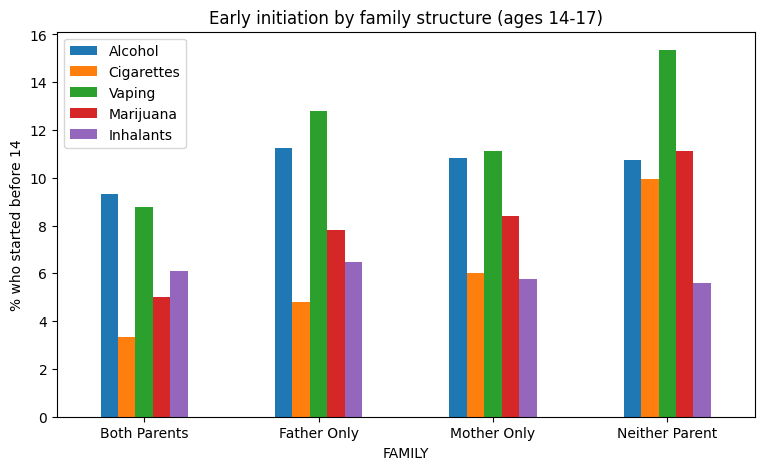

In [33]:
result.drop(columns="n").plot(kind="bar", figsize=(9, 5))
plt.ylabel("% who started before 14")
plt.title("Early initiation by family structure (ages 14-17)")
plt.xticks(rotation=0)
plt.show()

In [34]:
freq = {1: "Always", 2: "Sometimes", 3: "Seldom", 4: "Never"}
attitude = {1: "Neither approve nor disapprove", 2: "Somewhat disapprove", 3: "Strongly disapprove"}

factors = {
    "FAMILY":   None,   
    "POVERTY3": {1: "Below poverty", 2: "Up to 2x poverty", 3: "More than 2x poverty"},
    "YELSTGRD": {1: "A average", 2: "B average", 3: "C average", 4: "D or lower"},
    "YESCHFLT": {1: "Liked school a lot", 2: "Kind of liked", 3: "Didn't like much", 4: "Hated school"},
    "YMDEYR":   {1: "Depression past year", 2: "No depression"},
    "YEPCHKHW": freq,   # parents check homework
    "YEPHLPHW": freq,   # parents help with homework
    "YEPLMTSN": freq,   # parents limit time out with friends
    "YEPPROUD": freq,   # parents say they're proud
    "YEYARGUP": {1: "0 times", 2: "1-2 times", 3: "3-5 times", 4: "6-9 times", 5: "10+ times"},
    "YESTSALC": {1: "None", 2: "A few", 3: "Most", 4: "All"},
    "YEFMJEVR": attitude,   # how teen feels about friends using marijuana
    "YEPMJEVR": attitude,   # how parents would feel about teen trying marijuana
    "YERLGIMP": {1: "Strongly disagree", 2: "Disagree", 3: "Agree", 4: "Strongly agree"},
    "IRSEX":    {1: "Male", 2: "Female"},
    "YMDELT":   {1: "Depression ever", 2: "Never depressed"},
}

gap_rows = []
for factor, labels_for_factor in factors.items():
    table = pd.DataFrame()
    for name, flag, age in substances:
        table[name] = weighted_rate(older_teens, factor, "early_" + name.lower())
    table["n"] = older_teens[factor].value_counts()

    if labels_for_factor is not None:
        table = table.rename(index=labels_for_factor)

    print(factor)
    print(table)

    for name, flag, age in substances:
        gap_rows.append({
            "factor": factor,
            "substance": name,
            "gap": table[name].max() - table[name].min(),
        })

gaps = pd.DataFrame(gap_rows).pivot(index="factor", columns="substance", values="gap")
gaps["average_gap"] = gaps.mean(axis=1)

print("\nGap in percentage points (highest group minus lowest group)")
print(gaps.sort_values("average_gap", ascending=False))


FAMILY
                  Alcohol  Cigarettes     Vaping  Marijuana  Inhalants      n
FAMILY                                                                       
Both Parents     9.327413    3.350140   8.779832   4.990882   6.119009  20187
Father Only     11.243705    4.819302  12.800643   7.823932   6.481285   1365
Mother Only     10.825383    6.010090  11.105137   8.413437   5.755087   7623
Neither Parent  10.760485    9.942762  15.345625  11.128927   5.603871   1483
POVERTY3
                        Alcohol  Cigarettes     Vaping  Marijuana  Inhalants  \
POVERTY3                                                                       
Below poverty          8.445801    5.092082  10.872577   7.246696   4.370320   
Up to 2x poverty       9.598023    5.561628  11.788436   7.798862   5.964960   
More than 2x poverty  10.404851    3.604574   8.658160   5.215841   6.730403   

                          n  
POVERTY3                     
Below poverty          6942  
Up to 2x poverty       67

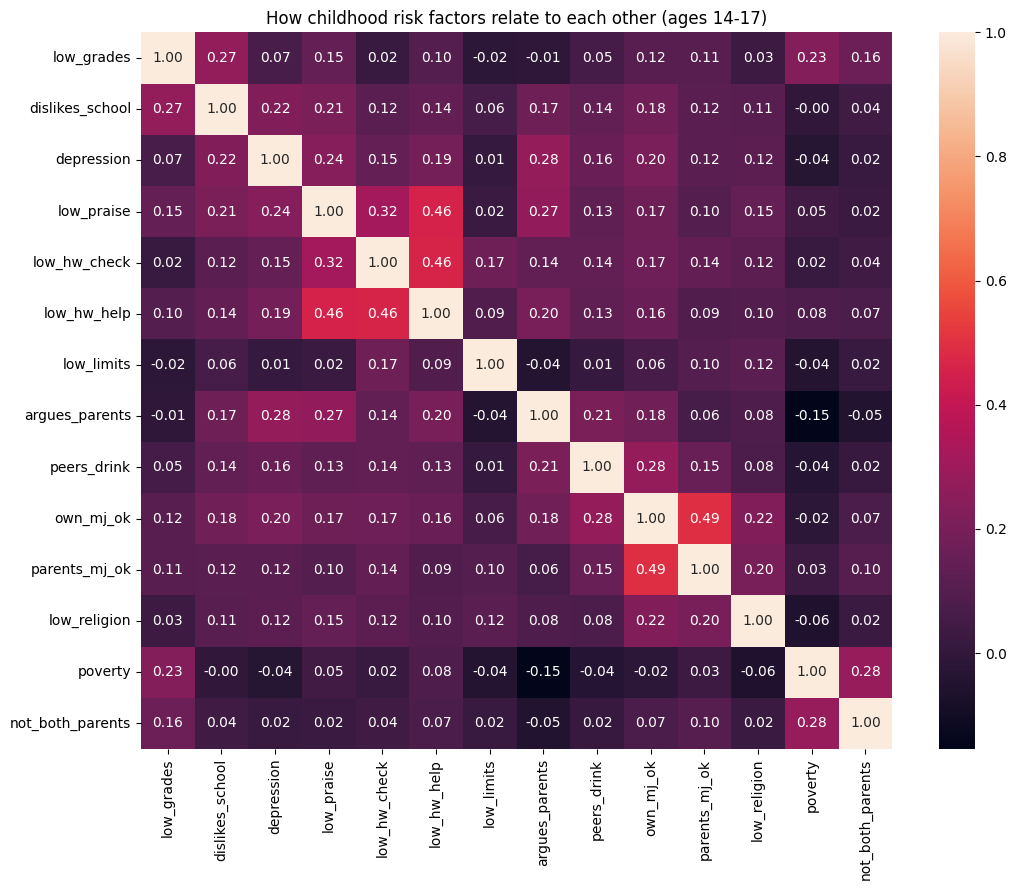

In [35]:
risk = pd.DataFrame({
    "low_grades": older_teens["YELSTGRD"],
    "dislikes_school":older_teens["YESCHFLT"],
    "depression": older_teens["YMDEYR"].map({1: 1, 2: 0}),
    "low_praise": older_teens["YEPPROUD"],
    "low_hw_check": older_teens["YEPCHKHW"],
    "low_hw_help":  older_teens["YEPHLPHW"],
    "low_limits":   older_teens["YEPLMTSN"],
    "argues_parents": older_teens["YEYARGUP"],
    "peers_drink": older_teens["YESTSALC"],
    "own_mj_ok": 4 - older_teens["YEFMJEVR"],
    "parents_mj_ok":  4 - older_teens["YEPMJEVR"],
    "low_religion": 5 - older_teens["YERLGIMP"],
    "poverty": 4 - older_teens["POVERTY3"],
    "not_both_parents": (older_teens["FAMILY"] != "Both Parents").astype(float).where(older_teens["FAMILY"].notna()),
})


corr = risk.corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f")
plt.title("How childhood risk factors relate to each other (ages 14-17)")
plt.tight_layout()
plt.show()

   substance        start  users_n  median_days_past_year  past_month_pct  \
0    Alcohol    Before 14     3134                    3.0            33.5   
1    Alcohol  14 or later     5904                    3.0            32.1   
2  Marijuana    Before 14     2154                   52.0            54.2   
3  Marijuana  14 or later     3873                   10.0            43.3   

   weekly_plus_pct  
0             16.7  
1              8.4  
2             49.9  
3             29.0  


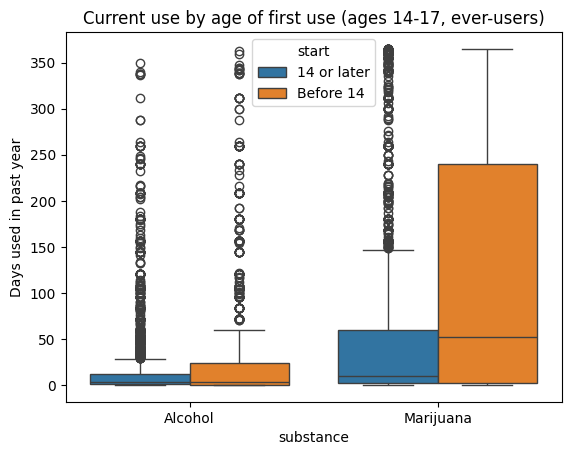

In [36]:
later_substances = [
    ["Alcohol",   "ALCFLAG", "IRALCFY", "IRALCRC"],
    ["Marijuana", "MRJFLAG", "IRMJFY",  "IRMJRC"],
]

summary_rows = []
plot_parts = []
for name, flag, days_col, recency_col in later_substances:
    early_col = "early_" + name.lower()

    # Ever-users aged 14-17 with a known start age
    users = older_teens[(older_teens[flag] == 1) & older_teens[early_col].notna()].copy()
    users["start"] = users[early_col].map({1: "Before 14", 0: "14 or later"})
    users["past_month"] = (users[recency_col] == 1).astype(int)
    users["weekly_plus"] = (users[days_col] >= 52).astype(int)

    past_month_pct = weighted_rate(users, "start", "past_month")
    weekly_pct = weighted_rate(users, "start", "weekly_plus")

    for start_group in ["Before 14", "14 or later"]:
        group = users[users["start"] == start_group]
        summary_rows.append({
            "substance": name,
            "start": start_group,
            "users_n": len(group),
            "median_days_past_year": group[days_col].median(),
            "past_month_pct": past_month_pct[start_group],
            "weekly_plus_pct": weekly_pct[start_group],
        })

    plot_parts.append(pd.DataFrame({
        "substance": name,
        "start": users["start"],
        "days_past_year": users[days_col],
    }))

summary = pd.DataFrame(summary_rows)
print(summary.round(1))

# Box plot: days used in past year, early vs later starters
plot_data = pd.concat(plot_parts, ignore_index=True)
sns.boxplot(data=plot_data, x="substance", y="days_past_year", hue="start")
plt.ylabel("Days used in past year")
plt.title("Current use by age of first use (ages 14-17, ever-users)")
plt.show()

In [211]:
dist_rows = []
for factor, labels_for_factor in factors.items():
    pct = weighted_pct(older_teens, factor)
    if labels_for_factor is not None:
        pct = pct.rename(index=labels_for_factor)
    missing_pct = older_teens[factor].isna().mean() * 100

    for answer, value in pct.items():
        dist_rows.append({
            "factor": factor,
            "answer": answer,
            "weighted_pct": round(value, 1),
            "missing_pct": round(missing_pct, 1),
        })

distribution = pd.DataFrame(dist_rows)
print(distribution.to_string(index=False))

  factor                         answer  weighted_pct  missing_pct
  FAMILY                   Both Parents          68.8          0.7
  FAMILY                    Father Only           4.1          0.7
  FAMILY                    Mother Only          22.1          0.7
  FAMILY                 Neither Parent           4.9          0.7
POVERTY3                  Below poverty          21.0          0.0
POVERTY3               Up to 2x poverty          21.2          0.0
POVERTY3           More than 2x poverty          57.8          0.0
YELSTGRD                      A average          42.4         11.8
YELSTGRD                      B average          35.4         11.8
YELSTGRD                      C average          16.6         11.8
YELSTGRD                     D or lower           5.6         11.8
YESCHFLT             Liked school a lot          20.7          7.4
YESCHFLT                  Kind of liked          51.2          7.4
YESCHFLT               Didn't like much          20.7         

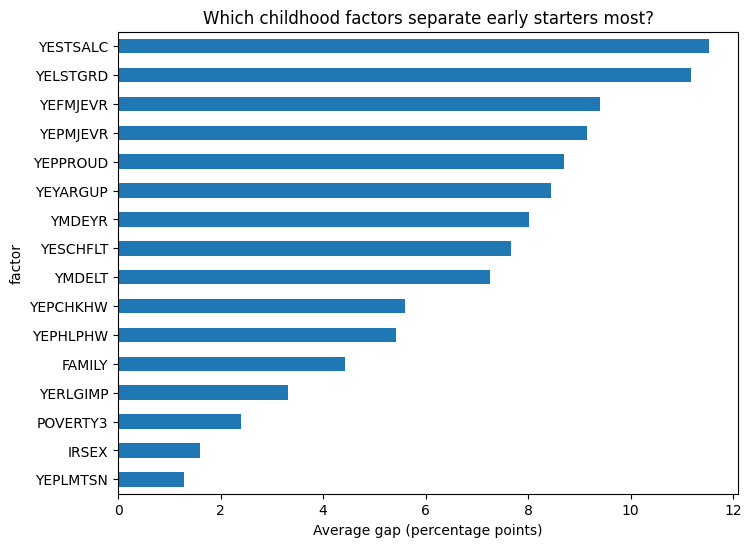

In [219]:
# Take the average gap for each factor, sorted smallest to largest
ranking = gaps["average_gap"].sort_values()

# Horizontal bar chart (strongest factor ends up at the top)
ranking.plot(kind="barh", figsize=(8, 6))
plt.xlabel("Average gap (percentage points)")
plt.title("Which childhood factors separate early starters most?")

plt.show()

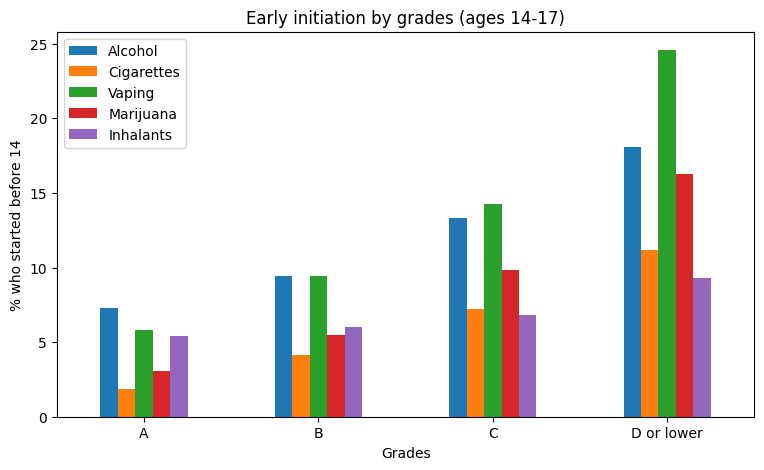

In [222]:
# Early-start % for each grade group, one column per substance
grades_table = pd.DataFrame()
for name, flag, age in substances:
    grades_table[name] = weighted_rate(older_teens, "YELSTGRD", "early_" + name.lower())

grades_table = grades_table.rename(index={1: "A", 2: "B", 3: "C", 4: "D or lower"})

grades_table.plot(kind="bar", figsize=(9, 5))
plt.ylabel("% who started before 14")
plt.xlabel("Grades")
plt.title("Early initiation by grades (ages 14-17)")
plt.xticks(rotation=0)
plt.show()

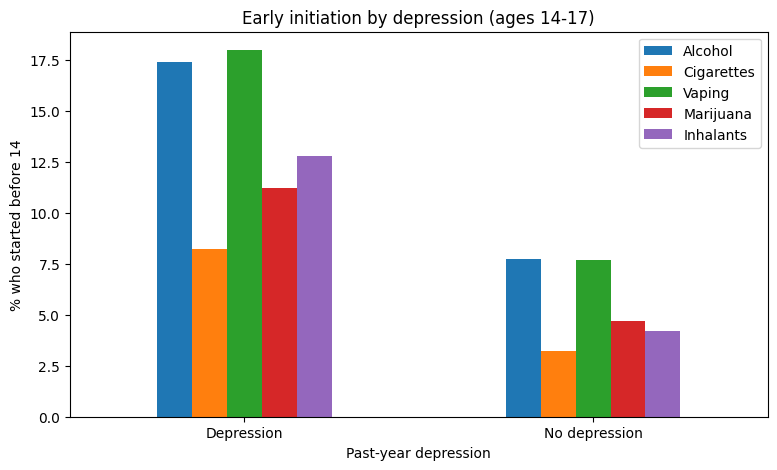

In [221]:
# Early-start % for depression yes/no, one column per substance
dep_table = pd.DataFrame()
for name, flag, age in substances:
    dep_table[name] = weighted_rate(older_teens, "YMDEYR", "early_" + name.lower())

dep_table = dep_table.rename(index={1: "Depression", 2: "No depression"})

dep_table.plot(kind="bar", figsize=(9, 5))
plt.ylabel("% who started before 14")
plt.xlabel("Past-year depression")
plt.title("Early initiation by depression (ages 14-17)")
plt.xticks(rotation=0)
plt.savefig("fig_depression.png", dpi=300, bbox_inches="tight")
plt.show()